# Practice Tasks: Matplotlib with Video Game Sales

You have learned how to draw charts with Matplotlib: line, bar, pie, histogram, box and scatter plots, subplots, customisation and saving figures. In this notebook you will do all of that **yourself, on a new dataset**.

## The dataset
**Video Game Sales** (Kaggle): sales of 16,598 video games, collected from vgchartz.com. **One row = one game.** The sales columns are in **millions of copies sold**.

**Download:** https://www.kaggle.com/datasets/gregorut/videogamesales (if the link has moved, search Kaggle for "Video Game Sales")
Sign in to Kaggle, click **Download**, unzip it and keep the file `vgsales.csv` in the same folder as this notebook.

| Column | Meaning |
|---|---|
| `Rank` | rank of the game by global sales |
| `Name` | name of the game |
| `Platform` | console or system (`Wii`, `PS2`, `DS`, `PC`, ...) |
| `Year` | year of release |
| `Genre` | `Action`, `Sports`, `Shooter`, `Role-Playing`, ... |
| `Publisher` | company that published the game |
| `NA_Sales`, `EU_Sales`, `JP_Sales`, `Other_Sales` | sales in North America, Europe, Japan and the rest of the world (millions) |
| `Global_Sales` | total sales worldwide (millions) |

## How to work
- Draw every chart with **Matplotlib**: create the Figure and Axes with `fig, ax = plt.subplots(...)` and call methods on `ax`. Use pandas and NumPy only to prepare the numbers.
- Each task gives a **goal**, **hints** (the functions you might use) and the **expected output**. Compare your chart and numbers with it. Small differences in colours or fonts are fine.
- Every chart needs a **title**, **axis labels with units** and, if it uses several colours, a **legend**.
- Some tasks ask you to explain something. Write it in the text cell below the code, in your own words.
- Do the tasks in order; later tasks reuse the code and data of earlier ones.
- When you finish, use *Restart kernel and run all* to check that your notebook runs from top to bottom without errors.

## Setup
Import `pandas` as `pd`, `numpy` as `np` and `matplotlib.pyplot` as `plt`.

In [4]:
!unzip -o "archive (4).zip"

Archive:  archive (4).zip
  inflating: vgsales.csv             


# Part 1: Prepare the data

### Task 1: Load, inspect and prepare the data

**Goal:**
1. Load `vgsales.csv` into a DataFrame called `df`. Show its shape and data types and count the missing values in each column. Find the smallest and the largest `Year`.
2. Prepare the data for charts: remove the rows where `Year` is missing, convert `Year` to whole numbers (`int`) and keep only the games released **from 1980 to 2016**.

**Hints:** `pd.read_csv`, `.shape`, `.dtypes`, `.isnull().sum()`, `.min()`, `.max()`, `.dropna(subset=[...])`, `.astype(int)`, a Boolean filter on `Year`

**Expected output**
- before: shape `(16598, 11)`; `Year` is a `float` column with **271** missing values; `Publisher` has **58** missing values; years run from **1980** to **2020**
- after: shape `(16323, 11)`; `Year` is an integer column from **1980** to **2016**
- You do not need to fix `Publisher`: no chart in this notebook uses it.

*All numbers in the later tasks assume you prepared the data exactly like this.*

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#load and inspect
df = pd.read_csv("vgsales.csv")
print("shape:", df.shape)
print("dtypes:" , df.dtypes)
print("missing values:" , df.isnull().sum())
print("min year:" , df["Year"].min())
print("max year:" , df["Year"].max())


#prepare the data
df= df. dropna(subset= ["Year"])
df["Year"] = df ["Year"]. astype(int)
df= df[df["Year"]>=1980]
df= df[df["Year"]<=2016]
print ("after shape:",df.shape)

shape: (16598, 11)
dtypes: Rank              int64
Name             object
Platform         object
Year            float64
Genre            object
Publisher        object
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object
missing values: Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64
min year: 1980.0
max year: 2020.0
after shape: (16323, 11)


*Your answer: why do we keep only the years up to 2016? (Look at how many games the dataset contains for 2017 and 2020.)*

# Part 2: Basic charts

### Task 2: Line chart: sales over the years

**Goal:** Draw a **line chart** of the **total** `Global_Sales` of the games released in each `Year`. Use a figure of size 9 × 4 inches, a marker on every point, a title, axis labels with units and a light grid.

**Hints:** `groupby("Year")["Global_Sales"].sum()`, `plt.subplots(figsize=)`, `ax.plot(x, y, marker=)`, `ax.set(title=, xlabel=, ylabel=)`, `ax.grid(alpha=)`

**Expected output**
- a line with **37 points** (1980 to 2016)
- it starts very low (about **11** million in 1980), grows slowly, then rises quickly from the mid-1990s
- the highest point is **2008, about 679 million**; after that the line falls, to about **71 million in 2016**
- the very last drop is partly because the data for 2016 is incomplete

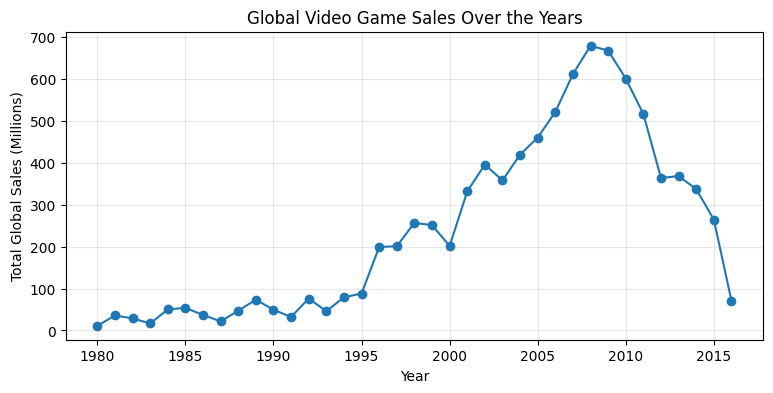

In [6]:
#In this task, we need to create a Line Chart that shows how total video game sales changed from 1980 to 2016.
import matplotlib.pyplot as plt

# Calculate total sales for each year
yearly_sales = df.groupby("Year")["Global_Sales"].sum()

# Create figure
fig, ax = plt.subplots(figsize=(9, 4))

# Draw line chart
ax.plot(yearly_sales.index, yearly_sales.values, marker="o")

# Add title and labels
ax.set(
    title="Global Video Game Sales Over the Years",
    xlabel="Year",
    ylabel="Total Global Sales (Millions)"
)

# Add grid
ax.grid(alpha=0.3) #- alpha=0.3 → Makes the grid lines light and transparent.

# Display chart
plt.show()

### Task 3: Bar chart: the best-selling genres

**Goal:** Draw a **vertical bar chart** of the **total** `Global_Sales` of the **8 best-selling genres**, from the highest bar to the lowest. Write the value on top of each bar and rotate the genre names if they overlap.

**Hints:** `groupby("Genre")["Global_Sales"].sum()`, `.sort_values(ascending=False).head(8)`, `ax.bar`, `ax.bar_label`, `ax.tick_params(axis="x", rotation=)`

**Expected output** (bar heights in millions, rounded)

| Genre | Action | Sports | Shooter | Role-Playing | Platform | Misc | Racing | Fighting |
|---|---|---|---|---|---|---|---|---|
| Total sales | 1,723 | 1,309 | 1,026 | 924 | 829 | 798 | 727 | 444 |

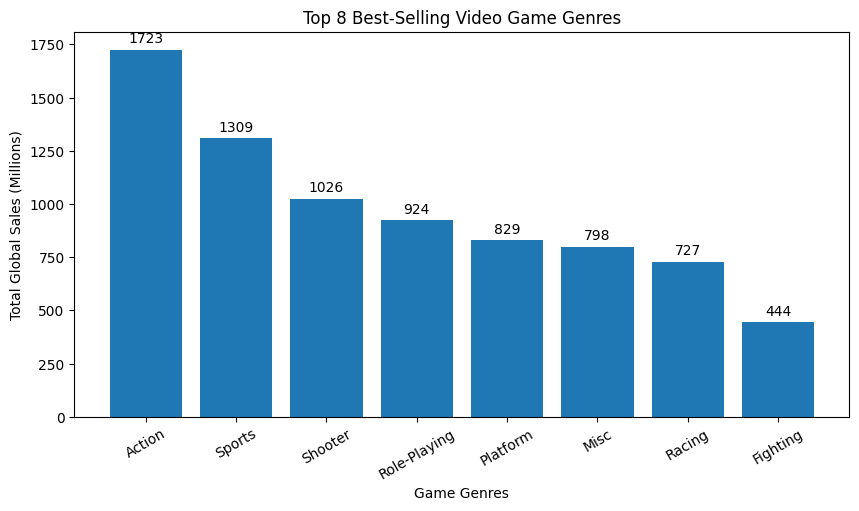

In [7]:
#we need to create a Vertical Bar Chart showing the 8 best-selling video game genres based on their total Global_Sales.
#The bars should be arranged from highest sales to lowest sales, with the sales value displayed above each bar.

import matplotlib.pyplot as plt

# Calculate total sales for each genre
genre_sales = df.groupby("Genre")["Global_Sales"].sum()

# Sort sales in descending order and select top 8
top_8 = genre_sales.sort_values(ascending=False).head(8)

# Create figure
fig, ax = plt.subplots(figsize=(10, 5))

# Create vertical bar chart
bars = ax.bar(top_8.index, top_8.values)  #ax.bar= Creates a vertical bar chart.
                                           #top_8.index → Genre names (X-axis).
                                           #top_8.values → Total sales (Y-axis).

# Add values on top of each bar
ax.bar_label(bars, fmt="%.0f", padding=3)  #fmt="%.0f" → Displays numbers without decimal places.
                                            #padding= add space b/t bar

# Add title and labels
ax.set(
    title="Top 8 Best-Selling Video Game Genres",
    xlabel="Game Genres",
    ylabel="Total Global Sales (Millions)"
)

# Rotate genre names
ax.tick_params(axis="x", rotation=30)

# Display chart
plt.show()

### Task 4: Horizontal bars: the busiest platforms

**Goal:** Draw a **horizontal bar chart** of the **number of games** released on each of the **10 platforms with the most games**. The platform with the most games must be at the **top**. Show the count at the end of each bar and leave room so that the labels do not touch the edge.

**Hints:** `value_counts().head(10)`, `.sort_values()` (the first bar is drawn at the bottom), `ax.barh`, `ax.bar_label`, `ax.set_xlim`

**Expected output** (from top to bottom)

| DS | PS2 | PS3 | Wii | X360 | PSP | PS | PC | GBA | XB |
|---|---|---|---|---|---|---|---|---|---|
| 2,132 | 2,127 | 1,304 | 1,290 | 1,235 | 1,197 | 1,189 | 943 | 811 | 803 |

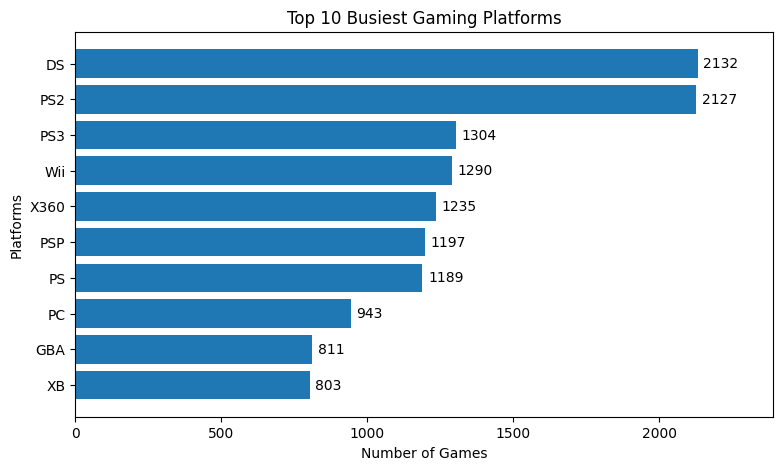

In [8]:
#we need to create a Horizontal Bar Chart showing the 10 platforms with the highest number of video games released.


import matplotlib.pyplot as plt

# Count games released on each platform
platform_counts = df["Platform"].value_counts().head(10) #head (10) =Selects the 10 platforms with the most games.

# Sort values from lowest to highest
top_10 = platform_counts.sort_values()

# Create figure
fig, ax = plt.subplots(figsize=(9, 5)) #ax → Graph plotting area.

# Create horizontal bar chart
bars = ax.barh(top_10.index, top_10.values)

# Add count labels at the end of bars
ax.bar_label(bars, padding=4)

# Set X-axis limit to leave space for labels
ax.set_xlim(0, top_10.max() * 1.12)

# Add title and labels
ax.set(
    title="Top 10 Busiest Gaming Platforms",
    xlabel="Number of Games",
    ylabel="Platforms"
)

# Display chart
plt.show()

### Task 5: Pie or donut chart: where are games sold?

**Goal:** Draw a **pie chart** (or a donut chart) of the share of the **total sales of each region**: North America, Europe, Japan, Other. Show the percentage on every slice and give the slices readable names.

**Hints:** `df[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]].sum()`, `ax.pie(..., labels=, autopct="%1.1f%%", startangle=90)`, for a donut: `wedgeprops=dict(width=0.45)`

**Expected output**
- North America **49.2%**, Europe **27.3%**, Japan **14.6%**, Other **9.0%** (the four slices add up to 100%)
- North America alone is about half of the world market.

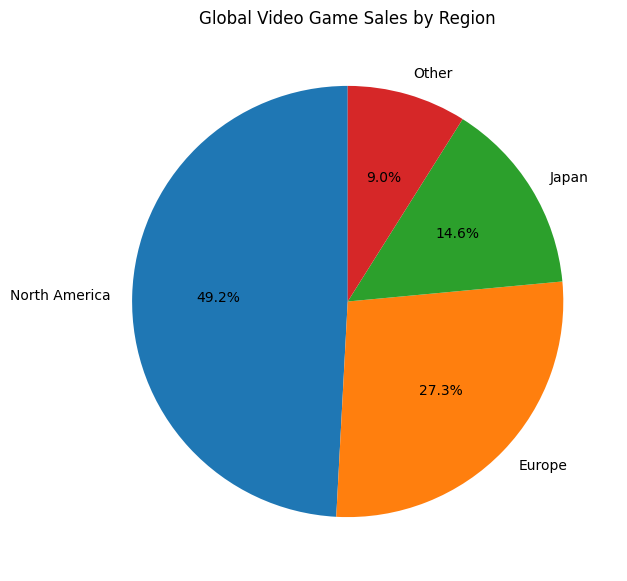

In [9]:
#we need to create a Pie Chart or Donut Chart showing the percentage of total video game sales in four different regions
#The purpose is to understand which region contributes the most to global video game sales.

import matplotlib.pyplot as plt

# Calculate total sales for each region
region_sales = df[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]].sum()

# Rename regions
labels = ["North America", "Europe", "Japan", "Other"]

# Create figure
fig, ax = plt.subplots(figsize=(7, 7))

# Create pie chart
ax.pie(
    region_sales,
    labels=labels,
    autopct="%1.1f%%",  # Displays percentages with one decimal place.
    startangle=90        # the first slice at 90 degrees.
)

# Add title
ax.set_title("Global Video Game Sales by Region")

# Display chart
plt.show()

In [13]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


*Your answer: would a bar chart be easier to read than a pie chart here? Why?*  A bar chart is better for comparing sales, while a pie chart is better for showing percentages.

# Part 3: Distributions and relationships

### Task 6: Histogram: how many copies does a game sell?

**Goal:**
1. Draw a **histogram** of `Global_Sales` for **all** games (30 bins).
2. Draw a second histogram (30 bins) for only the games that sold **2 million copies or less**. Add two vertical lines: the **mean** and the **median** of `Global_Sales` of **all** games (with a legend that shows their values).

Put both histograms next to each other in one figure.

**Hints:** `plt.subplots(1, 2)`, `ax.hist(values, bins=)`, a Boolean filter, `.mean()`, `.median()`, `ax.axvline(value, color=, linestyle=, label=)`, `ax.legend()`

**Expected output**
- left: almost all games are in **one huge bar** at the left (about **15,783 of the 16,323** games); a few hits sell tens of millions, so the x-axis stretches up to about 83
- right: a steep right-skewed shape: most games sell very little. The mean line (**about 0.54**) lies to the right of the median line (**about 0.17**)
- **15,487 games (94.9%)** sold 2 million copies or less

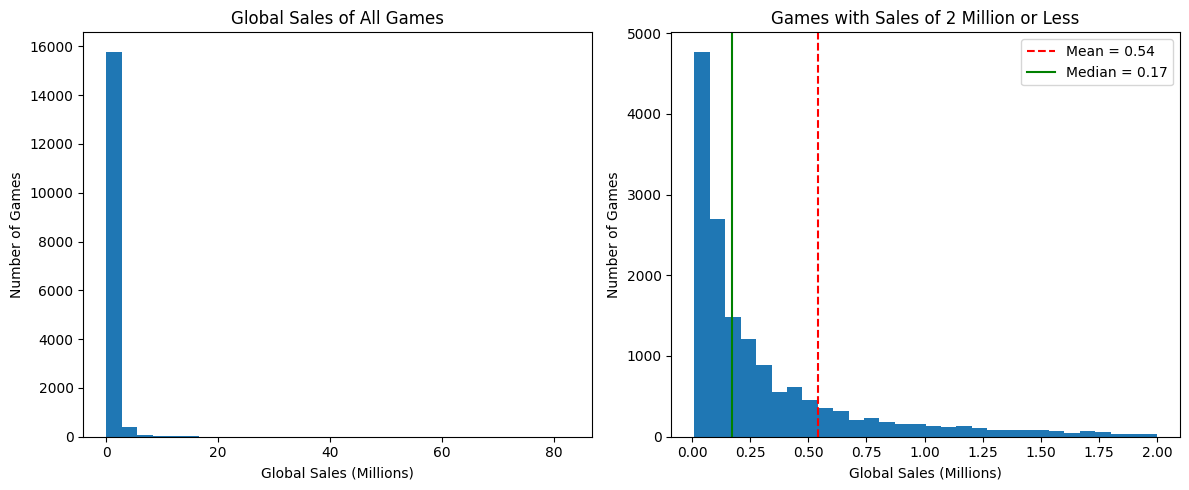

In [14]:
#we will draw two histogram for copies vids game sell

import matplotlib.pyplot as plt

# Select Global_Sales column
values = df["Global_Sales"].dropna()

# Filter games with sales of 2 million or less
filtered = values[values <= 2]

# Calculate mean and median of all games
mean_value = values.mean()
median_value = values.median()

# Create two histograms side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# First histogram: All games
axes[0].hist(values, bins=30) #- bins=30 → Divides sales into 30 groups.

axes[0].set(
    title="Global Sales of All Games",
    xlabel="Global Sales (Millions)",
    ylabel="Number of Games"
)

# Second histogram: Games with sales <= 2 million
axes[1].hist(filtered, bins=30)

# Add mean line
axes[1].axvline(
    mean_value,
    color="red",
    linestyle="--",
    label=f"Mean = {mean_value:.2f}"  #.2f → Shows two decimal places.
)

# Add median line
axes[1].axvline(
    median_value,
    color="green",
    linestyle="-",
    label=f"Median = {median_value:.2f}"
)

axes[1].set(
    title="Games with Sales of 2 Million or Less",        #94.9%
     xlabel="Global Sales (Millions)",              #of games sold 2 million copies or less.
     ylabel="Number of Games"
                                                   # Out of 16,323 games:
                                                       # 15,487 games sold 2 million or less.
                                                       # Only 836 games sold more than 2 million
)

# Show legend
axes[1].legend()

# Adjust spacing
plt.tight_layout()

# Display graphs
plt.show()

*Your answer: why is the mean larger than the median?*

### Task 7: Box plot: are some genres bigger hits than others?

**Goal:** Draw **box plots** of `Global_Sales` for the **5 genres with the most games** (one box per genre, with the mean marked). Use a **logarithmic y-axis**, because a few games sold far more than the typical game.

**Hints:** `value_counts().head(5).index`, a list with one Series per genre, `ax.boxplot(data, showmeans=True)`, `ax.set_xticks`, `ax.set_xticklabels`, `ax.set_yscale("log")`

**Expected output**
- genres (and number of games): Action (3,252), Sports (2,304), Misc (1,710), Role-Playing (1,469), Shooter (1,282)
- the medians are very similar, between **0.16 and 0.23 million**: Shooter has the highest, Misc the lowest
# - every genre has many dots (outliers) above the whiskers; the highest dot belongs to **Sports** (Wii Sports, **82.74** million)

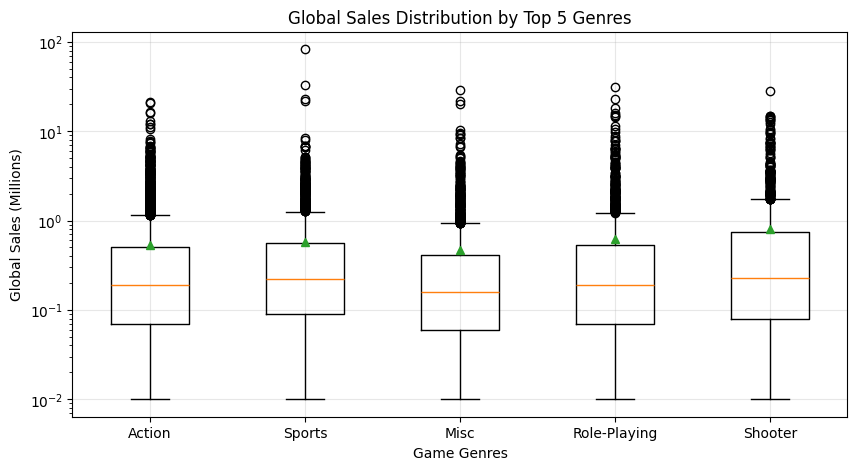

In [15]:
import matplotlib.pyplot as plt

# Find the 5 genres with the most games
top_genres = df["Genre"].value_counts().head(5).index

# Create a list of sales for each genre
data = [
    df.loc[df["Genre"] == genre, "Global_Sales"].dropna()
    for genre in top_genres
]

# Create figure
fig, ax = plt.subplots(figsize=(10, 5))

# Draw box plots
ax.boxplot(data, showmeans=True)

# Set genre names on X-axis
ax.set_xticks(range(1, len(top_genres) + 1))
ax.set_xticklabels(top_genres)

# Set logarithmic Y-axis
ax.set_yscale("log")

# Add title and labels
ax.set(
    title="Global Sales Distribution by Top 5 Genres",
    xlabel="Game Genres",
    ylabel="Global Sales (Millions)"
)

# Add grid
ax.grid(alpha=0.3)

# Display graph
plt.show()

### Task 8: Scatter plot: do North America and Europe buy the same games?

**Goal:** Draw a **scatter plot** with `NA_Sales` on the x-axis and `EU_Sales` on the y-axis, using only the games where **both** sales are greater than 0. Use a **log scale on both axes**, small semi-transparent dots (`alpha`), and write the correlation of the original (not logged) values in the title or print it.

**Hints:** a Boolean filter with `&`, `ax.scatter(x, y, s=, alpha=)`, `ax.set_xscale("log")`, `ax.set_yscale("log")`, `.corr()`

**Expected output**
- **9,597 points** forming a cloud that rises from the bottom left to the top right: games that sell well in North America also sell well in Europe
- horizontal and vertical stripes of dots at the low end: sales are rounded to 0.01 million
- correlation about **0.77**

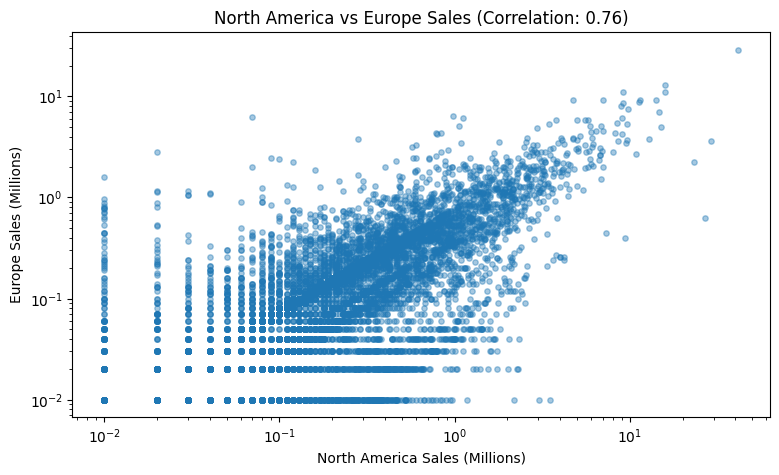

Correlation: 0.76


In [16]:
#we need to create a Scatter Plot to understand whether North America and Europe buy the same video games.
import matplotlib.pyplot as plt

# Filter games where both sales are greater than 0
filtered = df[(df["NA_Sales"] > 0) & (df["EU_Sales"] > 0)]

# Select sales columns
x = filtered["NA_Sales"]
y = filtered["EU_Sales"]

# Calculate correlation
correlation = x.corr(y)

# Create figure
fig, ax = plt.subplots(figsize=(9, 5))

# Create scatter plot
ax.scatter(x, y, s=15, alpha=0.4)

# Set logarithmic scales
ax.set_xscale("log")
ax.set_yscale("log")

# Add title and labels
ax.set(
    title=f"North America vs Europe Sales (Correlation: {correlation:.2f})",
    xlabel="North America Sales (Millions)",
    ylabel="Europe Sales (Millions)"
)

# Display graph
plt.show()

# Print correlation
print("Correlation:", round(correlation, 2))

# Part 4: Layout and customisation

### Task 9: Stacked bars: regions inside each genre

**Goal:** Draw a **stacked bar chart** of the sales of the **6 best-selling genres**. Each bar is one genre and is made of four segments: North America, Europe, Japan, Other. Use a different colour for each region and put the legend **outside** the plot, on the right.

**Hints:** `groupby("Genre")[[...]].sum()`, select the top 6 genres, `ax.bar(..., bottom=)` (the bottom of each new segment is the sum of the segments below it), `ax.legend(title=, bbox_to_anchor=(1.02, 1), loc="upper left")`

**Expected output**
- bars from left to right: Action, Sports, Shooter, Role-Playing, Platform, Misc (the Action bar is the tallest, about 1,723)
- North America is the biggest segment in every genre **except Role-Playing**, where **Japan (about 350 million) is bigger than North America (about 326 million)**

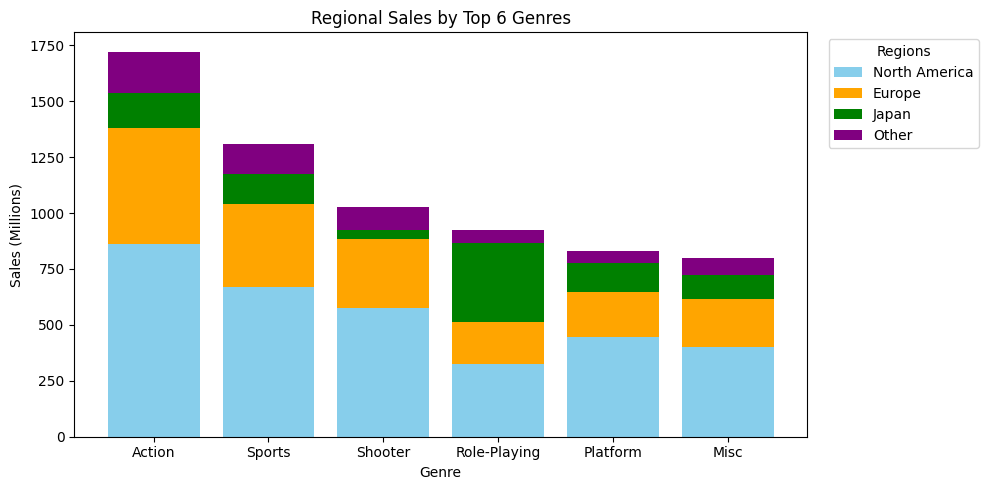

In [17]:
#A stacked bar chart shows the total sales of each genre, divided into four regions:
import matplotlib.pyplot as plt

# 1. Select regional sales columns
regions = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]

# 2. Calculate total sales for each genre
genre_sales = df.groupby("Genre")[regions].sum()

# 3. Select the 6 best-selling genres
top6 = genre_sales.sum(axis=1).sort_values(ascending=False).head(6).index

# 4. Arrange genres in the required order
genre_sales = genre_sales.loc[top6]

# 5. Create the stacked bar chart
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(genre_sales.index, genre_sales["NA_Sales"],
       label="North America", color="skyblue")

ax.bar(genre_sales.index, genre_sales["EU_Sales"],
       bottom=genre_sales["NA_Sales"],
       label="Europe", color="orange")

ax.bar(genre_sales.index, genre_sales["JP_Sales"],
       bottom=genre_sales["NA_Sales"] + genre_sales["EU_Sales"],
       label="Japan", color="green")

ax.bar(genre_sales.index, genre_sales["Other_Sales"],
       bottom=genre_sales["NA_Sales"] + genre_sales["EU_Sales"] + genre_sales["JP_Sales"],
       label="Other", color="purple")

# 6. Add title and labels
ax.set_title("Regional Sales by Top 6 Genres")
ax.set_xlabel("Genre")
ax.set_ylabel("Sales (Millions)")

# 7. Put legend outside the chart
ax.legend(title="Regions", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

*Your answer: what does this chart tell you about what Japanese players like?*

### Task 10: A dashboard with four charts

**Goal:** Put four of your charts into **one figure** with a 2 × 2 grid of Axes:
1. top left: the line chart of sales per year (Task 2)
2. top right: the bar chart of the best-selling genres (Task 3)
3. bottom left: the histogram of games with 2 million sales or less (Task 6, right chart)
4. bottom right: the scatter plot of North America vs Europe (Task 8)

Give every panel its own title and axis labels, add an overall title to the figure, and make sure that no labels overlap.

**Hints:** `plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)`, `axes[row, col]`, `fig.suptitle(...)`

**Expected output:** one figure with four clearly separated panels, with the same shapes as in the earlier tasks and one big title above them. Rotate the genre names in the bar panel if they overlap.

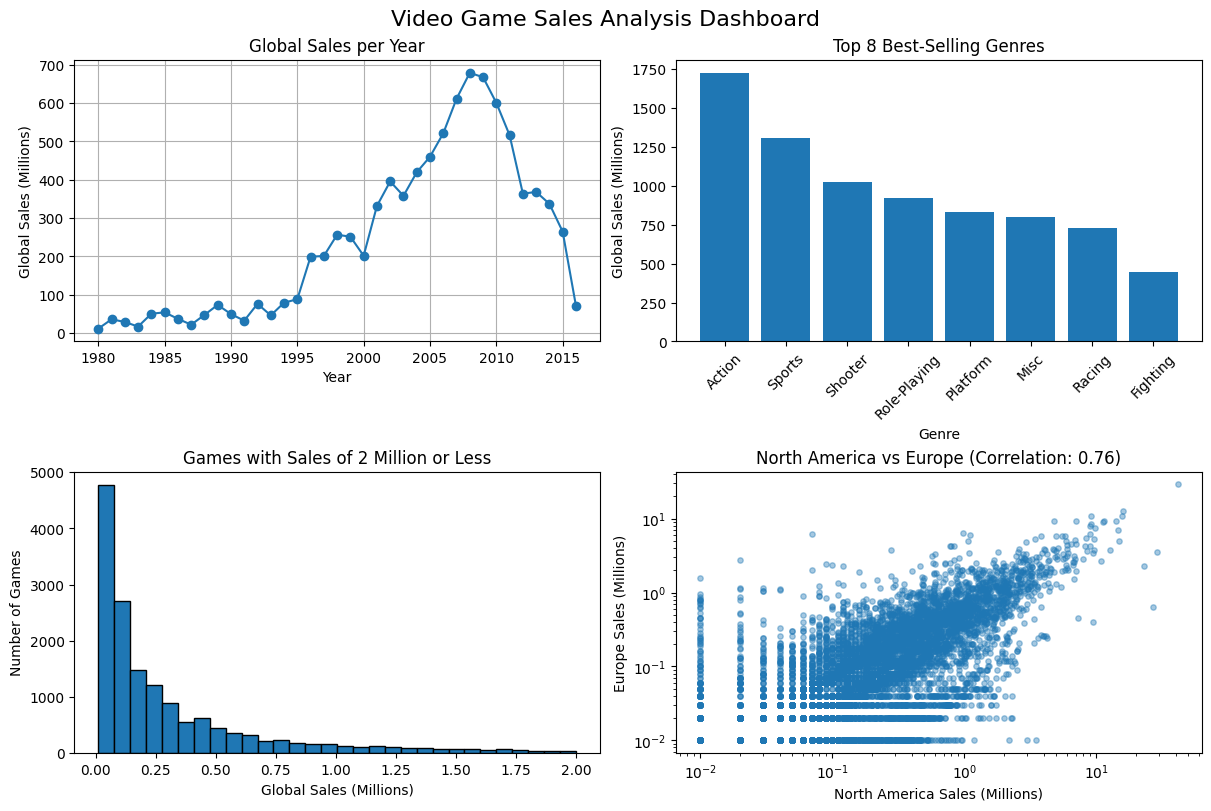

In [19]:
#In this task, we combine four charts into one figure using a 2 × 2 grid.
#We use plt.subplots(2, 2) to create four separate plotting areas.

import matplotlib.pyplot as plt

# Create a 2 × 2 dashboard
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8),
    constrained_layout=True
)

# --------------------------------
# 1. Top Left: Line Chart (Task 2)
# --------------------------------

yearly_sales = df.groupby("Year")["Global_Sales"].sum()

axes[0, 0].plot(
    yearly_sales.index,
    yearly_sales.values,
    marker="o"
)

axes[0, 0].set_title("Global Sales per Year")
axes[0, 0].set_xlabel("Year")
axes[0, 0].set_ylabel("Global Sales (Millions)")
axes[0, 0].grid(True)


# --------------------------------
# 2. Top Right: Bar Chart (Task 3)
# --------------------------------

genre_sales = df.groupby("Genre")["Global_Sales"].sum()
top_genres = genre_sales.sort_values(ascending=False).head(8)

axes[0, 1].bar(
    top_genres.index,
    top_genres.values
)

axes[0, 1].set_title("Top 8 Best-Selling Genres")
axes[0, 1].set_xlabel("Genre")
axes[0, 1].set_ylabel("Global Sales (Millions)")
axes[0, 1].tick_params(axis="x", rotation=45)


# --------------------------------
# 3. Bottom Left: Histogram (Task 6)
# --------------------------------

sales_under_2 = df.loc[df["Global_Sales"] <= 2, "Global_Sales"]

axes[1, 0].hist(
    sales_under_2,
    bins=30,
    edgecolor="black"
)

axes[1, 0].set_title("Games with Sales of 2 Million or Less")
axes[1, 0].set_xlabel("Global Sales (Millions)")
axes[1, 0].set_ylabel("Number of Games")


# --------------------------------
# 4. Bottom Right: Scatter Plot (Task 8)
# --------------------------------

filtered = df[
    (df["NA_Sales"] > 0) &
    (df["EU_Sales"] > 0)
]

x = filtered["NA_Sales"]
y = filtered["EU_Sales"]

correlation = x.corr(y)

axes[1, 1].scatter(x, y, s=15, alpha=0.4)

axes[1, 1].set_xscale("log")
axes[1, 1].set_yscale("log")

axes[1, 1].set_title(
    f"North America vs Europe (Correlation: {correlation:.2f})"
)
axes[1, 1].set_xlabel("North America Sales (Millions)")
axes[1, 1].set_ylabel("Europe Sales (Millions)")


# --------------------------------
# Overall Dashboard Title
# --------------------------------

fig.suptitle("Video Game Sales Analysis Dashboard", fontsize=16)

plt.show()

### Task 11: Make a chart presentation-ready, save it and write your findings

**Goal:**
1. Redraw the **line chart of Task 2** so that it tells a story:
   - a **title that states the message** (for example "Video game sales peaked in 2008")
   - an **annotation with an arrow** at the peak year, with the text of the peak value
   - the years **after the peak shaded** in grey
   - y-axis tick labels written like `200M`, `400M`, ...
   - the top and right frame lines removed
2. Save the figure as a **PNG** (200 dpi) and as a **PDF**, with the margins cropped. Print the names and sizes of the saved files.
3. In the text cell below, write **4 short findings** about video game sales. Each finding must contain **one number** from your charts.

**Hints:** `ax.annotate(text, xy=, xytext=, arrowprops=dict(arrowstyle="->"))`, `ax.axvspan(x1, x2, color=, alpha=)`, `FuncFormatter` from `matplotlib.ticker`, `ax.yaxis.set_major_formatter`, `ax.spines[["top", "right"]].set_visible(False)`, `fig.savefig(path, dpi=200, bbox_inches="tight")`, `pathlib.Path`

**Expected output**
- the chart looks like the line of Task 2 with an arrow pointing to **2008 (about 679M)**, a grey band from 2008 to 2016 and y labels such as `0M ... 600M`
- two files (a `.png` and a `.pdf`) exist after you run the code
- your findings should agree with your charts, for example: the peak year, the best-selling genre, the share of North America, the fact that most games sell very little

video_game_sales.png: 98.36 KB
video_game_sales.pdf: 13.82 KB


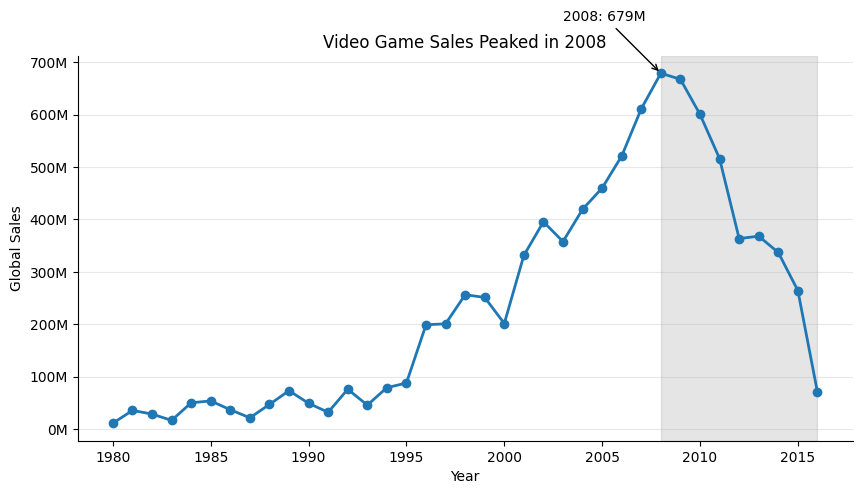

In [20]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from pathlib import Path

# 1. Calculate total global sales per year
yearly_sales = df.groupby("Year")["Global_Sales"].sum()

# 2. Find the peak year and peak sales
peak_year = yearly_sales.idxmax()
peak_sales = yearly_sales.max()

# 3. Create the figure
fig, ax = plt.subplots(figsize=(10, 5))

# 4. Draw the line chart
ax.plot(
    yearly_sales.index,
    yearly_sales.values,
    marker="o",
    linewidth=2,
    label="Global Sales"
)

# 5. Add a grey shaded area after the peak year
ax.axvspan(
    peak_year,
    yearly_sales.index.max(),
    color="grey",
    alpha=0.2
)

# 6. Add an annotation with an arrow at the peak
ax.annotate(
    f"{peak_year}: {peak_sales:.0f}M",
    xy=(peak_year, peak_sales),
    xytext=(peak_year - 5, peak_sales + 100),
    arrowprops=dict(arrowstyle="->"),
    fontsize=10
)

# 7. Format y-axis values with M
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"{value:.0f}M")
)

# 8. Add title and axis labels
ax.set_title("Video Game Sales Peaked in 2008")
ax.set_xlabel("Year")
ax.set_ylabel("Global Sales")

# 9. Remove top and right frame lines
ax.spines[["top", "right"]].set_visible(False)

# 10. Add grid
ax.grid(axis="y", alpha=0.3)

# 11. Save the chart
output_dir = Path(".")

png_path = output_dir / "video_game_sales.png"
pdf_path = output_dir / "video_game_sales.pdf"

fig.savefig(png_path, dpi=200, bbox_inches="tight")
fig.savefig(pdf_path, bbox_inches="tight")

# 12. Display saved file names and sizes
for path in [png_path, pdf_path]:
    print(f"{path.name}: {path.stat().st_size / 1024:.2f} KB")

plt.show()

*Your findings:*

1.Video game sales reached their highest point in 2008, with approximately 679 million global sales.
2. Action was best
3.North America was the largest sales region, contributing approximately 49.2% of total global video game sales.
4.Approximately 94.9% of video games had global sales of 2 million or less, showing that most games sold relatively few copies.

---
**Before you submit:** restart the kernel, run all cells from top to bottom, and make sure there are no errors.